In [1]:
# %% 1. Imports, logging setup, and configuration
from __future__ import annotations

import json
import logging
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, StratifiedKFold,
    learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


def setup_logging(log_file: str = "pipeline.log") -> logging.Logger:
    """Configure a logger that writes to both the console and a file.

    Args:
        log_file: path to the log file to create/append.

    Returns:
        A configured Logger instance.
    """
    logger = logging.getLogger("breast_cancer_pipeline")
    logger.setLevel(logging.INFO)
    logger.handlers.clear()

    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%H:%M:%S")
    console = logging.StreamHandler()
    console.setFormatter(fmt)
    file_handler = logging.FileHandler(log_file)
    file_handler.setFormatter(fmt)

    logger.addHandler(console)
    logger.addHandler(file_handler)
    return logger


log = setup_logging()


@dataclass
class Config:
    """Single place to tune the whole pipeline."""
    random_state: int = 42
    test_size: float = 0.2
    outer_folds: int = 5
    inner_folds: int = 3
    scoring: str = "roc_auc"
    param_grid: dict[str, list[Any]] = field(default_factory=lambda: {
        "clf__n_estimators": [100, 200, 400],
        "clf__max_depth": [None, 4, 8, 12],
        "clf__min_samples_split": [2, 5, 10],
    })
    report_path: str = "breast_cancer_report.json"
    model_path: str = "breast_cancer_model.joblib"


CFG = Config()
np.random.seed(CFG.random_state)

In [2]:
# %% 2. Pipeline class
class BreastCancerPipeline:
    """Owns the full lifecycle: load data, explore, train, tune, evaluate, persist.

    Keeping this as a class (rather than loose script steps) means every
    intermediate result (data, trained model, metrics) is kept as state on
    `self`, so later steps and the final report can reuse it without
    re-computing or passing a long chain of arguments around.
    """

    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.df: pd.DataFrame | None = None
        self.X_train = self.X_test = self.y_train = self.y_test = None
        self.best_model: Pipeline | None = None
        self.cv_results: dict[str, np.ndarray] = {}
        self.metrics: dict[str, float] = {}

    def load_data(self) -> "BreastCancerPipeline":
        """Load the sklearn breast cancer dataset into a labeled DataFrame."""
        raw = load_breast_cancer()
        self.df = pd.DataFrame(raw.data, columns=raw.feature_names)
        self.df["target"] = raw.target  # 0 = malignant, 1 = benign
        log.info("Loaded dataset with shape %s", self.df.shape)
        return self

    def explore(self) -> "BreastCancerPipeline":
        """Print summary stats and plot class balance + correlations."""
        df = self.df
        print(df.head())
        print("\nMissing values:", df.isnull().sum().sum())
        print("\nClass balance:\n", df["target"].value_counts(normalize=True).rename("proportion"))

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
        sns.countplot(x="target", data=df, ax=axes[0], palette="Set2")
        axes[0].set_xticklabels(["Malignant (0)", "Benign (1)"])
        axes[0].set_title("Class Distribution")

        top_corr = df.corr()["target"].abs().sort_values(ascending=False)[1:11]
        sns.barplot(x=top_corr.values, y=top_corr.index, ax=axes[1], palette="viridis")
        axes[1].set_title("Top 10 Features Correlated with Target")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(9, 7))
        sns.heatmap(df[list(top_corr.index) + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
        plt.title("Correlation Heatmap - Top 10 Features")
        plt.tight_layout()
        plt.show()
        return self

    def split(self) -> "BreastCancerPipeline":
        """Create a stratified train/test split."""
        X = self.df.drop(columns="target")
        y = self.df["target"]
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y, test_size=self.cfg.test_size,
            random_state=self.cfg.random_state, stratify=y
        )
        log.info("Train size: %d | Test size: %d", self.X_train.shape[0], self.X_test.shape[0])
        return self

    @staticmethod
    def _build_pipelines(random_state: int) -> dict[str, Pipeline]:
        """Bundle scaler + model so scaling never leaks test-fold information."""
        return {
            "Logistic Regression": Pipeline([
                ("scaler", StandardScaler()),
                ("clf", LogisticRegression(max_iter=2000, random_state=random_state)),
            ]),
            "Random Forest": Pipeline([
                ("scaler", StandardScaler()),
                ("clf", RandomForestClassifier(random_state=random_state)),
            ]),
            "SVM (RBF)": Pipeline([
                ("scaler", StandardScaler()),
                ("clf", SVC(kernel="rbf", probability=True, random_state=random_state)),
            ]),
        }

    def compare_models(self) -> "BreastCancerPipeline":
        """Cross-validate each candidate model and plot the comparison."""
        outer_cv = StratifiedKFold(n_splits=self.cfg.outer_folds, shuffle=True,
                                   random_state=self.cfg.random_state)
        pipelines = self._build_pipelines(self.cfg.random_state)
        try:
            for name, pipe in pipelines.items():
                scores = cross_val_score(pipe, self.X_train, self.y_train,
                                         cv=outer_cv, scoring=self.cfg.scoring)
                self.cv_results[name] = scores
                log.info("%-22s CV %s: %.4f +/- %.4f", name, self.cfg.scoring,
                        scores.mean(), scores.std())
        except Exception:
            log.exception("Model comparison failed")
            raise

        plt.figure(figsize=(6, 4))
        sns.boxplot(data=list(self.cv_results.values()))
        plt.xticks(range(len(self.cv_results)), list(self.cv_results.keys()), rotation=15)
        plt.ylabel(f"{self.cfg.scoring} (CV)")
        plt.title("Model Comparison - Cross-Validation")
        plt.tight_layout()
        plt.show()
        return self

    def tune_best_model(self) -> "BreastCancerPipeline":
        """Tune Random Forest with nested cross-validation.

        The outer loop gives an unbiased estimate of how the *tuning process*
        performs (not just the final chosen hyperparameters), which is more
        rigorous than reporting the inner GridSearchCV score directly.
        """
        outer_cv = StratifiedKFold(n_splits=self.cfg.outer_folds, shuffle=True,
                                   random_state=self.cfg.random_state)
        inner_cv = StratifiedKFold(n_splits=self.cfg.inner_folds, shuffle=True,
                                   random_state=self.cfg.random_state)
        base_pipe = self._build_pipelines(self.cfg.random_state)["Random Forest"]

        grid = GridSearchCV(base_pipe, self.cfg.param_grid, cv=inner_cv,
                            scoring=self.cfg.scoring, n_jobs=-1)

        nested_scores = cross_val_score(grid, self.X_train, self.y_train,
                                        cv=outer_cv, scoring=self.cfg.scoring)
        log.info("Nested CV %s (unbiased estimate): %.4f +/- %.4f",
                self.cfg.scoring, nested_scores.mean(), nested_scores.std())
        self.metrics["nested_cv_roc_auc_mean"] = float(nested_scores.mean())
        self.metrics["nested_cv_roc_auc_std"] = float(nested_scores.std())

        # Final fit on all training data to pick the single model we'll ship
        grid.fit(self.X_train, self.y_train)
        log.info("Best params (final fit): %s", grid.best_params_)
        self.best_model = grid.best_estimator_
        return self

    def learning_curve_check(self) -> "BreastCancerPipeline":
        """Plot training vs. validation score to visually check for over/underfitting."""
        cv = StratifiedKFold(n_splits=self.cfg.outer_folds, shuffle=True,
                             random_state=self.cfg.random_state)
        train_sizes, train_scores, val_scores = learning_curve(
            self.best_model, self.X_train, self.y_train, cv=cv,
            scoring=self.cfg.scoring, train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
        )
        plt.figure(figsize=(7, 4.5))
        plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Training score")
        plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="Validation score")
        plt.xlabel("Training examples")
        plt.ylabel(self.cfg.scoring)
        plt.title("Learning Curve - Tuned Random Forest")
        plt.legend()
        plt.tight_layout()
        plt.show()
        return self

    def evaluate(self) -> "BreastCancerPipeline":
        """Compute the full metric suite on the held-out test set and plot diagnostics."""
        pred = self.best_model.predict(self.X_test)
        proba = self.best_model.predict_proba(self.X_test)[:, 1]

        self.metrics.update({
            "test_accuracy": float(accuracy_score(self.y_test, pred)),
            "test_precision": float(precision_score(self.y_test, pred)),
            "test_recall": float(recall_score(self.y_test, pred)),
            "test_f1": float(f1_score(self.y_test, pred)),
            "test_roc_auc": float(roc_auc_score(self.y_test, proba)),
            "test_pr_auc": float(average_precision_score(self.y_test, proba)),
        })
        for k, v in self.metrics.items():
            print(f"{k:28s}: {v:.4f}")

        print("\nClassification report:\n",
              classification_report(self.y_test, pred, target_names=["Malignant", "Benign"]))

        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
        ConfusionMatrixDisplay(
            confusion_matrix(self.y_test, pred), display_labels=["Malignant", "Benign"]
        ).plot(cmap="Blues", ax=axes[0], colorbar=False)
        axes[0].set_title("Confusion Matrix")
        RocCurveDisplay.from_predictions(self.y_test, proba, ax=axes[1])
        axes[1].set_title("ROC Curve")
        PrecisionRecallDisplay.from_predictions(self.y_test, proba, ax=axes[2])
        axes[2].set_title("Precision-Recall Curve")
        plt.tight_layout()
        plt.show()
        return self

    def explain(self) -> "BreastCancerPipeline":
        """Plot permutation importance - a robust, model-agnostic explainability method."""
        perm = permutation_importance(
            self.best_model, self.X_test, self.y_test, n_repeats=20,
            random_state=self.cfg.random_state, scoring=self.cfg.scoring
        )
        importance = pd.Series(
            perm.importances_mean, index=self.X_test.columns
        ).sort_values(ascending=False)[:10]

        plt.figure(figsize=(8, 5))
        sns.barplot(x=importance.values, y=importance.index, palette="mako")
        plt.title("Top 10 Features by Permutation Importance")
        plt.xlabel(f"Mean decrease in {self.cfg.scoring}")
        plt.tight_layout()
        plt.show()
        return self

    def save(self) -> "BreastCancerPipeline":
        """Persist the trained model and a JSON metrics report to disk."""
        try:
            joblib.dump(self.best_model, self.cfg.model_path)
            Path(self.cfg.report_path).write_text(json.dumps(self.metrics, indent=2))
            log.info("Saved model to %s and report to %s", self.cfg.model_path, self.cfg.report_path)
        except Exception:
            log.exception("Failed to save model/report")
            raise
        return self

    def predict_sample(self, index: int = 0) -> None:
        """Run and print a single-sample prediction as a usage demo."""
        sample = self.X_test.iloc[[index]]
        pred_label = self.best_model.predict(sample)[0]
        pred_proba = self.best_model.predict_proba(sample)[0][pred_label]
        actual_label = self.y_test.iloc[index]
        print(f"Predicted: {'Benign' if pred_label == 1 else 'Malignant'} "
              f"(confidence: {pred_proba:.2%})")
        print(f"Actual:    {'Benign' if actual_label == 1 else 'Malignant'}")


13:11:45 | INFO | Loaded dataset with shape (569, 31)
INFO:breast_cancer_pipeline:Loaded dataset with shape (569, 31)


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

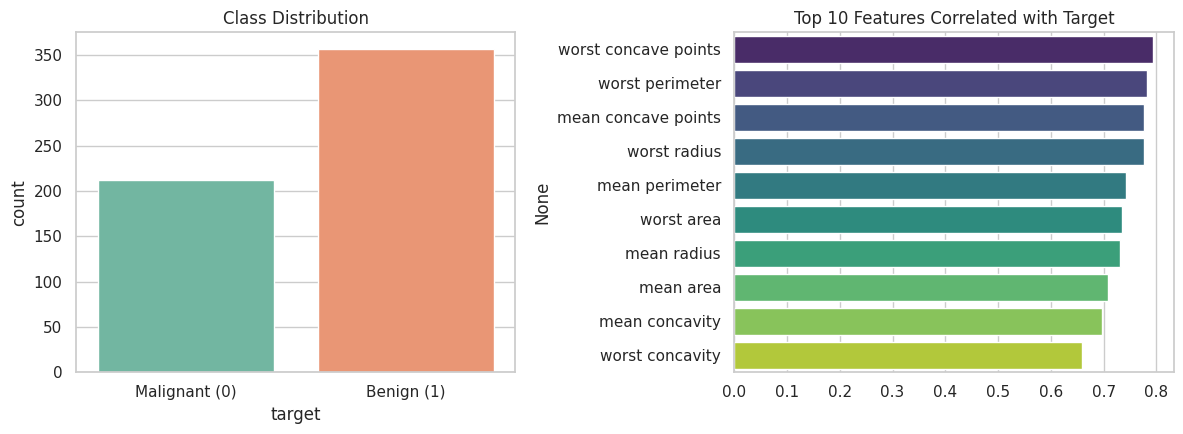

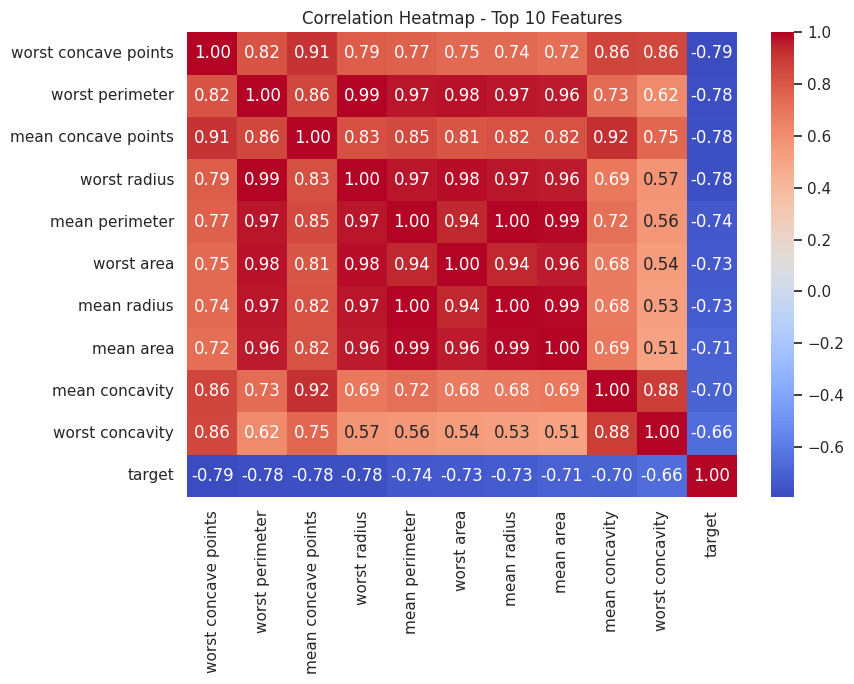

13:11:46 | INFO | Train size: 455 | Test size: 114
INFO:breast_cancer_pipeline:Train size: 455 | Test size: 114
13:11:46 | INFO | Logistic Regression    CV roc_auc: 0.9959 +/- 0.0050
INFO:breast_cancer_pipeline:Logistic Regression    CV roc_auc: 0.9959 +/- 0.0050
13:11:47 | INFO | Random Forest          CV roc_auc: 0.9896 +/- 0.0083
INFO:breast_cancer_pipeline:Random Forest          CV roc_auc: 0.9896 +/- 0.0083
13:11:47 | INFO | SVM (RBF)              CV roc_auc: 0.9956 +/- 0.0048
INFO:breast_cancer_pipeline:SVM (RBF)              CV roc_auc: 0.9956 +/- 0.0048


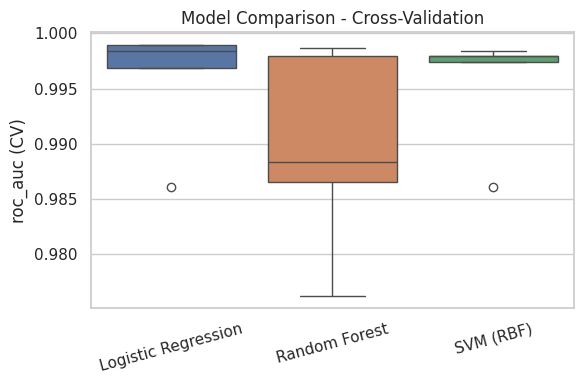

13:14:14 | INFO | Nested CV roc_auc (unbiased estimate): 0.9893 +/- 0.0086
INFO:breast_cancer_pipeline:Nested CV roc_auc (unbiased estimate): 0.9893 +/- 0.0086
13:14:46 | INFO | Best params (final fit): {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}
INFO:breast_cancer_pipeline:Best params (final fit): {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 100}


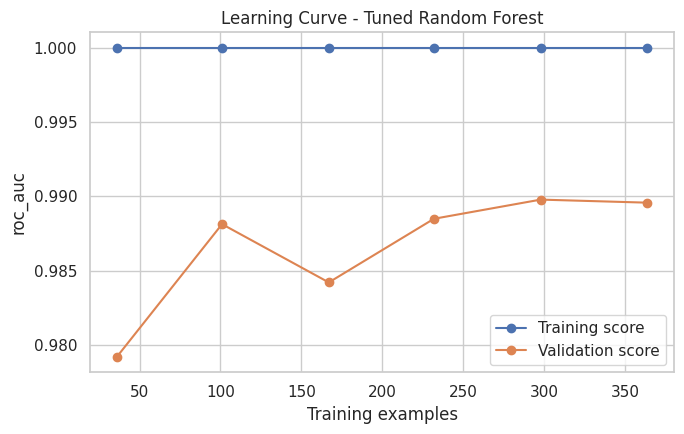

nested_cv_roc_auc_mean      : 0.9893
nested_cv_roc_auc_std       : 0.0086
test_accuracy               : 0.9561
test_precision              : 0.9589
test_recall                 : 0.9722
test_f1                     : 0.9655
test_roc_auc                : 0.9939
test_pr_auc                 : 0.9964

Classification report:
               precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



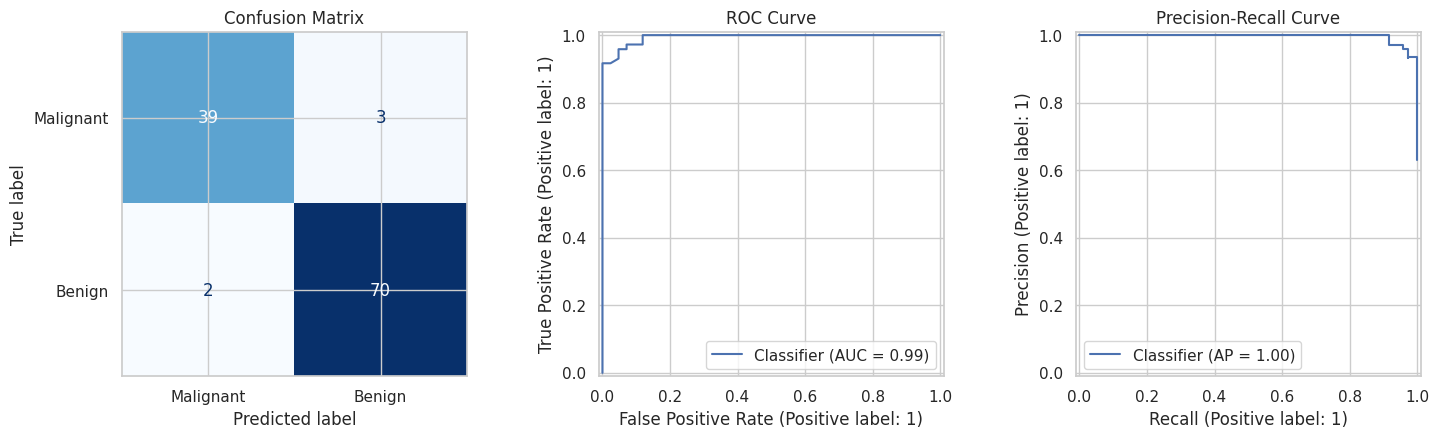

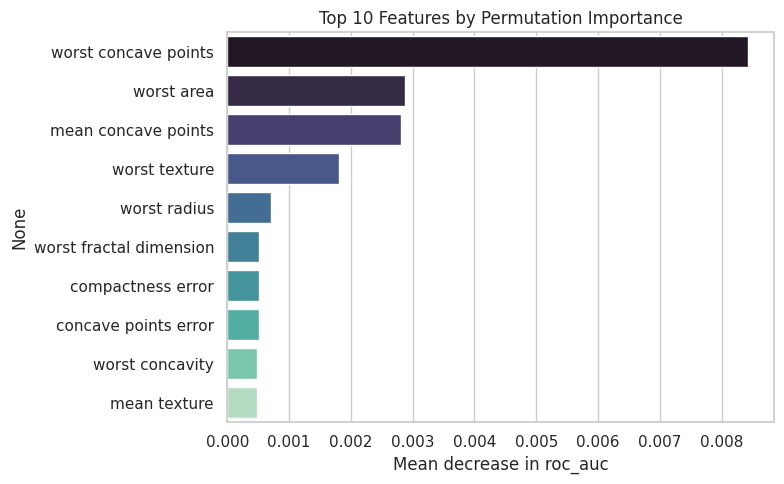

13:14:55 | INFO | Saved model to breast_cancer_model.joblib and report to breast_cancer_report.json
INFO:breast_cancer_pipeline:Saved model to breast_cancer_model.joblib and report to breast_cancer_report.json


Predicted: Malignant (confidence: 100.00%)
Actual:    Malignant


In [3]:
# %% 3. Run the full pipeline
pipeline = (
    BreastCancerPipeline(CFG)
    .load_data()
    .explore()
    .split()
    .compare_models()
    .tune_best_model()
    .learning_curve_check()
    .evaluate()
    .explain()
    .save()
)
pipeline.predict_sample()